# Semana 9 — Backbone, CBAM y cabeza de detección

**Entregable del enunciado (sección 6):** *Backbone, CBAM y cabeza de detección implementados; overfit intencional sobre un batch pequeño como prueba de correctitud; primeras predicciones de bounding boxes visualmente razonables.*

Este notebook **no contiene lógica propia**: ejecuta los scripts de `src/` en el orden del entregable y muestra e interpreta sus salidas. Se corre desde el Mac (necesita `data/raw/`). Secciones:

0. Entorno y pruebas
1. Preprocesamiento de entrada al modelo (ventana ósea + gamma 1.5) y revisión visual de los 100 casos
2. Arquitectura: backbone + CBAM + cabeza de detección + NMS
3. Overfit intencional (prueba de correctitud)
4. Caché de cortes y primer entrenamiento multi-paciente (con y sin CBAM)
5. Curvas y primeras bounding boxes en validación
6. Resumen para `docs/resumen_semana9.md`

> Uso académico. El sistema no ha sido validado clínicamente.

## 0. Entorno y pruebas

In [2]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

REPO = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(REPO); sys.path.insert(0, str(REPO / 'src'))
print('Repo:', REPO, '| Python:', sys.executable)

def run(cmd):
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
    for line in p.stdout:
        if 'Warning' not in line and 'warn' not in line:
            print(line, end='', flush=True)
    return p.wait()

Repo: /Users/mariavalencia/Downloads/pengwin_fixed | Python: /Users/mariavalencia/Downloads/pengwin_fixed/.venv/bin/python


## 1. Preprocesamiento de entrada al modelo

`pengwin_io.window_hu` hace: clip [−1024, 3000] HU → ventana ósea C400/W1800 → [0,1] → **gamma 1.5**. Gamma reemplazó a CLAHE tras la asesoría (semana 9): el barrido `experimento_normalizacion.py` (166 configuraciones NGC-CLAHE, 5 casos) mostró que CLAHE bajaba el contraste-ruido a la mitad y triplicaba el ruido del tejido blando; gamma solo ganó en todos los casos. El valor 1.5 se fijó por brillo del hueso (ver `comparar_gamma.py`).

Las máscaras óseas del Visualizador 1 siguen operando sobre HU crudo; gamma solo toca la imagen que entra al modelo.

$ python src/comparar_gamma.py
  caso variante                   CNR  brillo hueso  ruido blando
------------------------------------------------------------------
   001 ventaneo (referencia)     3.77         0.400        0.0389
   001 CLAHE actual (descartado)    1.79         0.626        0.1356
   001 gamma 1.2                 4.05         0.339        0.0358
   001 gamma 1.5 (elegido)       4.51         0.268        0.0305
   001 gamma 2.0                 5.39         0.188        0.0222
   001 gamma 2.2                 5.79         0.165        0.0194
   025 ventaneo (referencia)     6.59         0.359        0.0154
   025 CLAHE actual (descartado)    3.67         0.529        0.0502
   025 gamma 1.2                 7.13         0.295        0.0137
   025 gamma 1.5 (elegido)       7.92         0.221        0.0112
   025 gamma 2.0                 9.25         0.139        0.0076
   025 gamma 2.2                 9.82         0.117        0.0065
   033 ventaneo (referencia)     4.15 

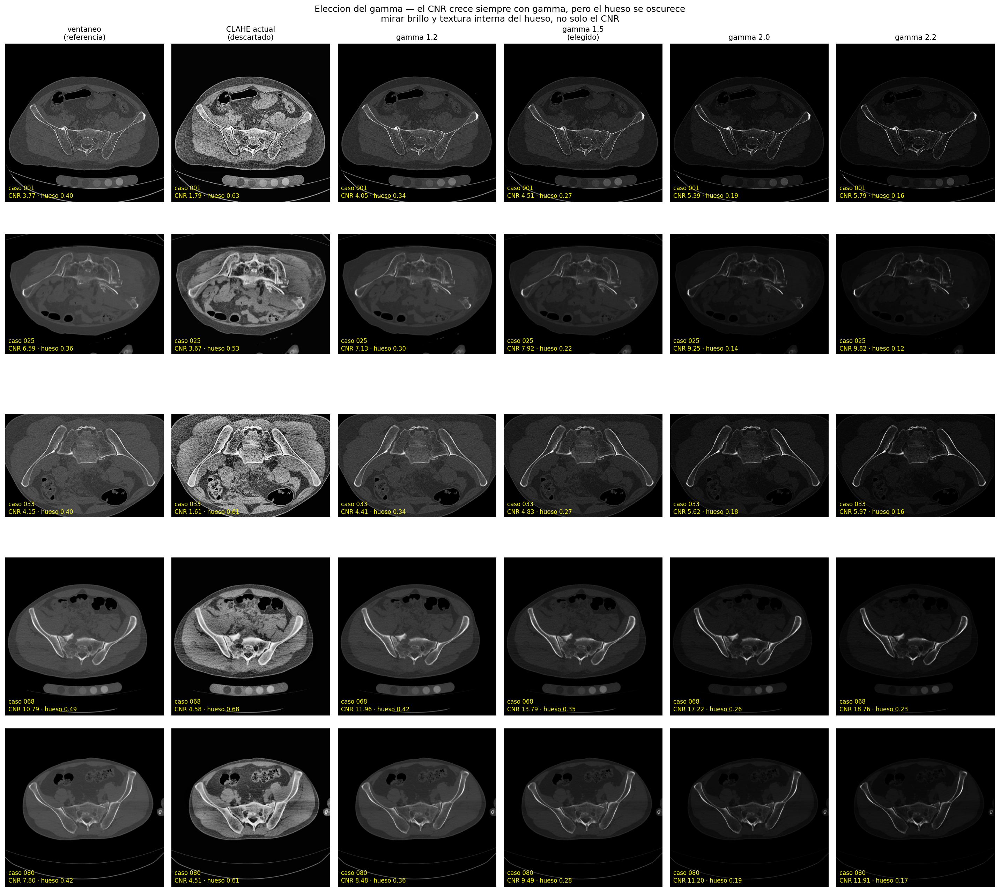

In [2]:
# Comparación ventaneo vs CLAHE anterior vs escalera de gamma (5 casos de referencia)
run('python src/comparar_gamma.py')
display(Image('outputs/eda/comparacion_gamma.png', width=1100))

### 1.1 Revisión visual de los 100 casos preprocesados

Para cada caso: el corte axial con más hueso etiquetado, tal como entra al modelo (gamma 1.5), con el contorno de la máscara en rojo. Criterio de revisión: el hueso debe verse claro y con textura interna; el tejido blando uniforme y oscuro; sin granulado. Abajo se calcula además el brillo medio del hueso por caso para detectar casos atípicos.

In [10]:
from pengwin_io import load_case, window_hu, resize_slice, resize_label_slice
from experimento_normalizacion import corte_con_mas_hueso

casos = [f'{i:03d}' for i in range(1, 101)]
brillo = {}
fig, axes = plt.subplots(10, 10, figsize=(22, 22))
for ax, cid in zip(axes.ravel(), casos):
    c = load_case(cid); z = corte_con_mas_hueso(c)
    img = resize_slice(window_hu(c.image[z]), 256); lab = resize_label_slice(c.label[z], 256)
    brillo[cid] = float(img[lab > 0].mean())
    ax.imshow(img, cmap='gray', vmin=0, vmax=1); ax.contour(lab > 0, levels=[0.5], colors='r', linewidths=0.4)
    ax.set_title(f'{cid}  b={brillo[cid]:.2f}', fontsize=7); ax.axis('off')
plt.tight_layout(); Path('outputs/figures').mkdir(parents=True, exist_ok=True)
fig.savefig('outputs/figures/revision_preprocesamiento_100_casos.png', dpi=110); plt.show()

/var/folders/0q/q32rr6wj7fn7mzz_ymx2jrww0000gn/T/ipykernel_43275/2080116680.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig('outputs/figures/revision_preprocesamiento_100_casos.png', dpi=110); plt.show()


In [11]:
vals = np.array(list(brillo.values())); ids = np.array(list(brillo.keys()))
z = (vals - vals.mean()) / vals.std()
print(f'Brillo medio del hueso (gamma 1.5): media {vals.mean():.3f}, mín {vals.min():.3f} ({ids[vals.argmin()]}), máx {vals.max():.3f} ({ids[vals.argmax()]})')
print('Casos atípicos (|z| > 2):', [(i, round(v, 3)) for i, v, zz in zip(ids, vals, z) if abs(zz) > 2])
plt.figure(figsize=(12, 3)); plt.bar(ids, vals); plt.xticks(rotation=90, fontsize=6); plt.ylabel('brillo hueso'); plt.title('Brillo medio del hueso por caso tras el preprocesamiento'); plt.tight_layout(); plt.show()

Brillo medio del hueso (gamma 1.5): media 0.296, mín 0.188 (034), máx 0.398 (076)
Casos atípicos (|z| > 2): [(np.str_('013'), np.float64(0.203)), (np.str_('026'), np.float64(0.212)), (np.str_('027'), np.float64(0.193)), (np.str_('034'), np.float64(0.188)), (np.str_('076'), np.float64(0.398)), (np.str_('095'), np.float64(0.189))]


/var/folders/0q/q32rr6wj7fn7mzz_ymx2jrww0000gn/T/ipykernel_43275/1261166791.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.figure(figsize=(12, 3)); plt.bar(ids, vals); plt.xticks(rotation=90, fontsize=6); plt.ylabel('brillo hueso'); plt.title('Brillo medio del hueso por caso tras el preprocesamiento'); plt.tight_layout(); plt.show()


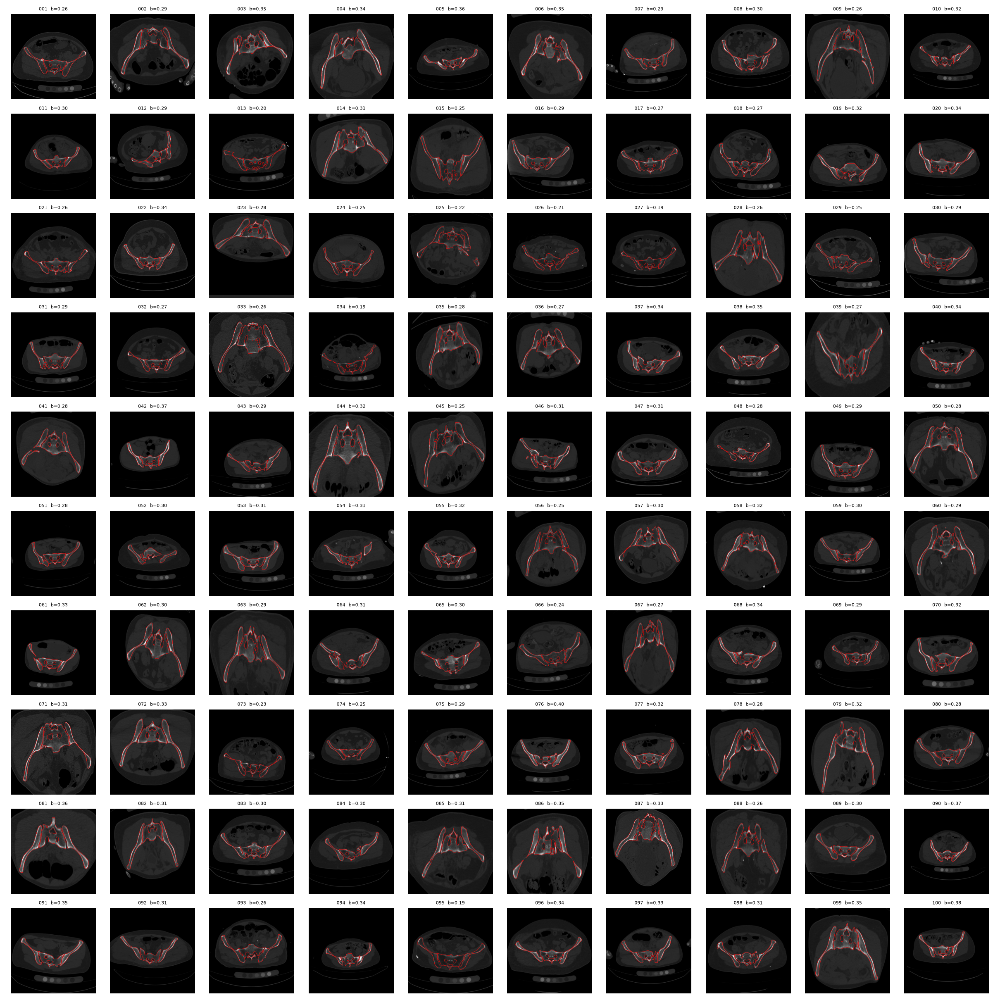

In [13]:
%matplotlib inline
display(Image('outputs/figures/revision_preprocesamiento_100_casos.png', width=1400))

**Lectura esperada:** el caso 025 aparece como el más oscuro (histograma óseo corrido ~150–250 HU, kernel de reconstrucción distinto). Gamma es global y no lo corrige; queda documentado como limitación. Si al revisar la cuadrícula algún caso se ve mal (hueso apagado, contorno fuera del hueso), anótalo aquí:

- Casos revisados: 100 / 100
- Observaciones: _(completar)_

## 2. Arquitectura

`week9_detection.py`: `FundidoraBackbone` (4 bloques convolucionales, reducción ×16, escrito desde cero) → `CBAM` (atención de canal y espacial, antes de la bifurcación a cabezas) → `GridDetectionHead` (grid 16×16 para 256 px; por celda: objectness, caja `(cx, cy, w, h)` y clase sacro / coxal izq / coxal der) → `nms` escrito en PyTorch. Pérdida: BCE objectness + Smooth L1 caja + CE clase. `use_cbam=False` deja la rama de ablación.

In [12]:
import torch
from week9_detection import FundidoraBackbone, CBAM, GridDetectionHead
import week9_detection as w9
x = torch.rand(1, 1, 256, 256)
for cbam in (True, False):
    kw = {'use_cbam': cbam} if 'use_cbam' in w9.FundidoraBackbone.__init__.__code__.co_varnames else {}
    bb = FundidoraBackbone(base_channels=32, **kw); f = bb(x)
    head = GridDetectionHead(bb.out_channels); out = head(f)
    n = sum(p.numel() for p in bb.parameters()) + sum(p.numel() for p in head.parameters())
    print(f'CBAM={cbam}: mapa de características {tuple(f.shape)} → salida detección {tuple(out.shape)} | parámetros {n:,}')

CBAM=True: mapa de características (1, 256, 16, 16) → salida detección (1, 16, 16, 8) | parámetros 1,773,322
CBAM=False: mapa de características (1, 256, 16, 16) → salida detección (1, 16, 16, 8) | parámetros 1,765,032


## 3. Overfit intencional (prueba de correctitud)

Caso 001, 2 cortes, 150 épocas. Criterio del enunciado: la pérdida debe bajar al menos 4×. No mide desempeño: prueba que la cadena máscara → target de grid → backbone/CBAM → cabeza → pérdida → NMS está bien conectada.

$ python src/train_overfit_detection.py --output outputs/week9_overfit_detection.pth
epoch 0001 loss=1.67265 obj=0.17755 box=0.09368 cls=1.02670
epoch 0015 loss=0.10941 obj=0.10388 box=0.00108 cls=0.00011
epoch 0030 loss=0.04746 obj=0.04414 box=0.00052 cls=0.00071
epoch 0045 loss=0.01782 obj=0.01754 box=0.00003 cls=0.00015
epoch 0060 loss=0.00815 obj=0.00806 box=0.00001 cls=0.00006
epoch 0075 loss=0.00461 obj=0.00456 box=0.00000 cls=0.00004
epoch 0090 loss=0.00307 obj=0.00303 box=0.00000 cls=0.00003
epoch 0105 loss=0.00225 obj=0.00222 box=0.00000 cls=0.00002
epoch 0120 loss=0.00174 obj=0.00171 box=0.00000 cls=0.00002
epoch 0135 loss=0.00140 obj=0.00137 box=0.00000 cls=0.00002
epoch 0150 loss=0.00115 obj=0.00113 box=0.00000 cls=0.00002

Dispositivo: cpu
CBAM: si
Codificacion: 0 reubicadas, 0 descartadas
Pérdida inicial: 1.67265 | final: 0.00115
Reducción: 1452.1x
Predicciones del primer corte: [{'box': [0.5997626781463623, 0.57426518201828, 0.6033607721328735, 0.5897939801216125], 'scor

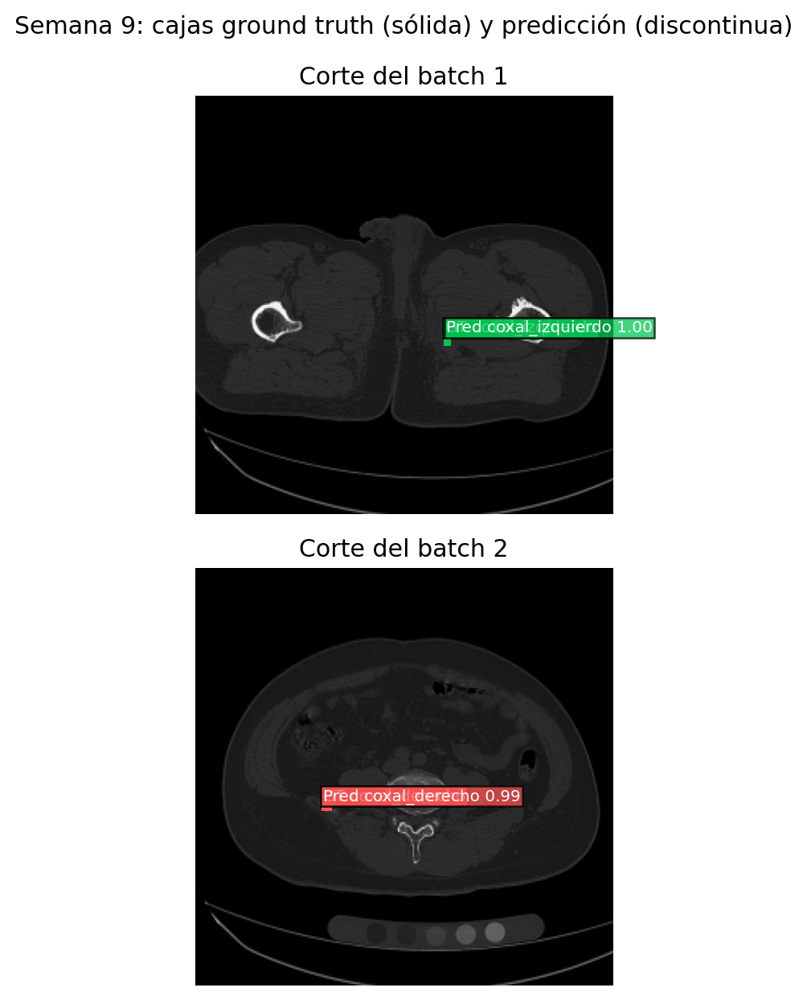

In [14]:
run('python src/train_overfit_detection.py --output outputs/week9_overfit_detection.pth')
run('python src/visualize_overfit_detection.py --checkpoint outputs/week9_overfit_detection.pth --output outputs/figures/week9_detection_overfit.png')
display(Image('outputs/figures/week9_detection_overfit.png', width=900))

## 4. Caché y primer entrenamiento multi-paciente

Caché de 4 cortes por caso, 24 casos de train / 15 de val (configuración de la semana 9), generado con el preprocesamiento actual (gamma). Luego dos entrenamientos de 35 épocas: **con CBAM** (modelo) y **sin CBAM** (ablación). Selección del checkpoint por **F1 de detección a IoU ≥ 0.5** (el IoU medio no castiga cajas sobrantes). En Mac con chip Apple usa la GPU integrada; cada entrenamiento tarda del orden de 10–20 min.

In [3]:
%matplotlib inline

In [4]:
run('python src/prepare_week9_detection_data.py --output data/cache/week9_detection_slices.npz')

$ python src/prepare_week9_detection_data.py --output data/cache/week9_detection_slices.npz

Preparando train: 100%|██████████| 24/24 [00:09<00:00,  2.49it/s]

Preparando val: 100%|██████████| 15/15 [00:04<00:00,  3.50it/s]

Preparando test: 0it [00:00, ?it/s]
Preparando test: 0it [00:00, ?it/s]
Cache: data/cache/week9_detection_slices.npz | cortes=156 | train=96 | val=60 | test=0


0

In [5]:
run('python src/train_week9_detection.py --output outputs/week9_det_cbam32.pth')

$ python src/train_week9_detection.py --output outputs/week9_det_cbam32.pth
Codificacion del target: 0 regiones reubicadas por colision de celda, 0 descartadas
Modelo: 32 canales base, CBAM si

epoch 001 train_loss=1.6314 F1=0.000 P=0.000 R=0.000 FP=0 iou=0.000  <- mejor
epoch 004 train_loss=0.4972 F1=0.008 P=0.011 R=0.006 FP=86 iou=0.029  <- mejor
epoch 005 train_loss=0.3116 F1=0.112 P=0.072 R=0.256 FP=545 iou=0.293  <- mejor
epoch 006 train_loss=0.1892 F1=0.143 P=0.101 R=0.244 FP=355 iou=0.301  <- mejor
epoch 008 train_loss=0.1075 F1=0.218 P=0.144 R=0.451 FP=440 iou=0.410  <- mejor
epoch 009 train_loss=0.1048 F1=0.225 P=0.155 R=0.415 FP=372 iou=0.358  <- mejor
epoch 010 train_loss=0.1168 F1=0.266 P=0.182 R=0.494 FP=363 iou=0.428  <- mejor
epoch 013 train_loss=0.0950 F1=0.283 P=0.211 R=0.427 FP=261 iou=0.389  <- mejor
epoch 015 train_loss=0.0784 F1=0.217 P=0.137 R=0.518 FP=535 iou=0.460
epoch 018 train_loss=0.0466 F1=0.291 P=0.214 R=0.457 FP=276 iou=0.411  <- mejor
epoch 019 train_los

0

In [6]:
run('python src/train_week9_detection.py --no-cbam --output outputs/week9_det_nocbam32.pth')

$ python src/train_week9_detection.py --no-cbam --output outputs/week9_det_nocbam32.pth
Codificacion del target: 0 regiones reubicadas por colision de celda, 0 descartadas
Modelo: 32 canales base, CBAM no (rama de ablacion)

epoch 001 train_loss=1.7342 F1=0.000 P=0.000 R=0.000 FP=0 iou=0.000  <- mejor
epoch 004 train_loss=0.5561 F1=0.021 P=0.067 R=0.012 FP=28 iou=0.025  <- mejor
epoch 005 train_loss=0.3646 F1=0.097 P=0.079 R=0.128 FP=246 iou=0.178  <- mejor
epoch 006 train_loss=0.2546 F1=0.123 P=0.089 R=0.201 FP=339 iou=0.248  <- mejor
epoch 009 train_loss=0.1724 F1=0.127 P=0.078 R=0.341 FP=659 iou=0.348  <- mejor
epoch 010 train_loss=0.1835 F1=0.213 P=0.176 R=0.268 FP=206 iou=0.275  <- mejor
epoch 013 train_loss=0.0704 F1=0.265 P=0.176 R=0.530 FP=406 iou=0.448  <- mejor
epoch 014 train_loss=0.0589 F1=0.329 P=0.222 R=0.634 FP=365 iou=0.480  <- mejor
epoch 015 train_loss=0.0461 F1=0.356 P=0.247 R=0.634 FP=317 iou=0.512  <- mejor
epoch 016 train_loss=0.0378 F1=0.366 P=0.260 R=0.616 FP=28

0

## 5. Curvas y primeras bounding boxes

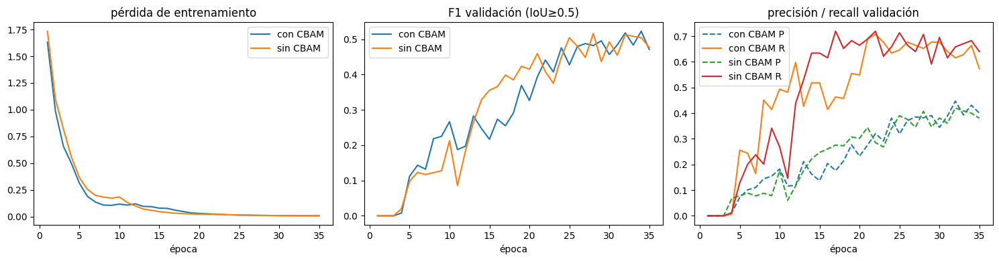

modelo      época      F1       P       R     IoU    FP   pred
con CBAM       34   0.523   0.431   0.665   0.504   144    253
sin CBAM       28   0.517   0.407   0.707   0.536   169    285


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
resumen = {}
for name, path in [('con CBAM', 'outputs/week9_det_cbam32.json'), ('sin CBAM', 'outputs/week9_det_nocbam32.json')]:
    if not Path(path).exists(): continue
    h = json.load(open(path)); hist = h['historial']; ep = [r['epoch'] for r in hist]
    axes[0].plot(ep, [r['train_loss'] for r in hist], label=name); axes[1].plot(ep, [r['f1'] for r in hist], label=name)
    axes[2].plot(ep, [r['precision'] for r in hist], '--', label=f'{name} P'); axes[2].plot(ep, [r['recall'] for r in hist], label=f'{name} R')
    best = hist[h['mejor_epoca'] - 1]; resumen[name] = best
for ax, t in zip(axes, ['pérdida de entrenamiento', 'F1 validación (IoU≥0.5)', 'precisión / recall validación']): ax.set_title(t); ax.set_xlabel('época'); ax.legend()
plt.tight_layout(); fig.savefig('outputs/figures/week9_curvas_cbam_vs_nocbam.png', dpi=120); plt.show()
print(f"{'modelo':10s} {'época':>6s} {'F1':>7s} {'P':>7s} {'R':>7s} {'IoU':>7s} {'FP':>5s} {'pred':>6s}")
for name, b in resumen.items():
    print(f"{name:10s} {b['epoch']:6d} {b['f1']:7.3f} {b['precision']:7.3f} {b['recall']:7.3f} {b['iou_medio']:7.3f} {int(b['falsos_positivos']):5d} {int(b['n_pred']):6d}")

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 014 --output outputs/figures/week9_detection_validation_014.png
Guardado: outputs/figures/week9_detection_validation_014.png


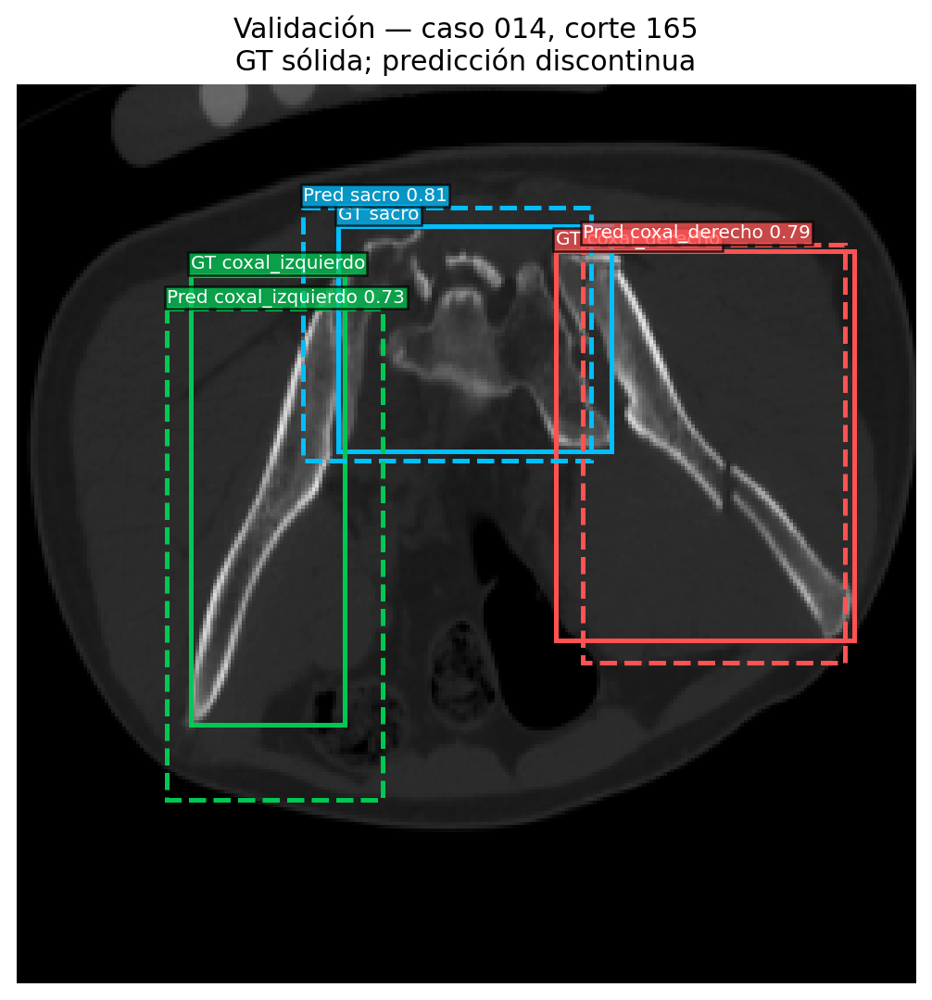

In [8]:
run('python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 014 --output outputs/figures/week9_detection_validation_014.png')
display(Image('outputs/figures/week9_detection_validation_014.png', width=900))

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 014 --output outputs/figures/week9_val_014.png
Guardado: outputs/figures/week9_val_014.png


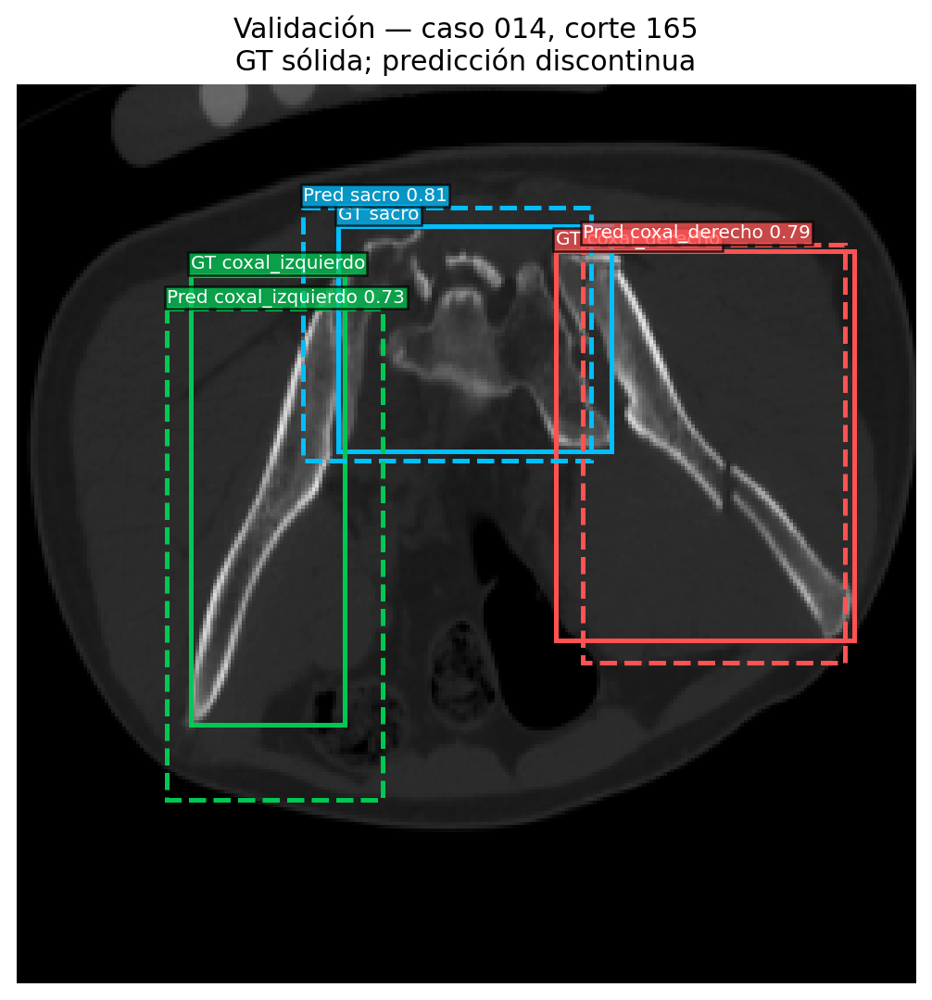

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 019 --output outputs/figures/week9_val_019.png
Guardado: outputs/figures/week9_val_019.png


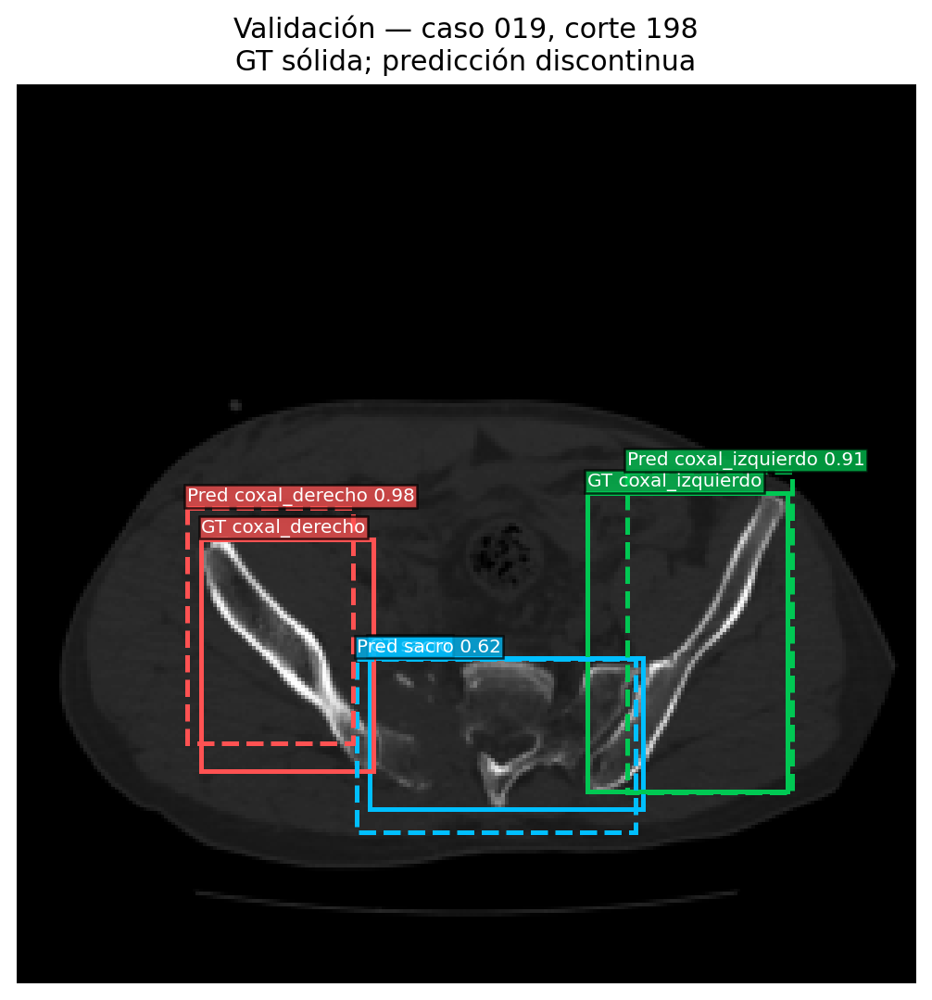

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 024 --output outputs/figures/week9_val_024.png
Guardado: outputs/figures/week9_val_024.png


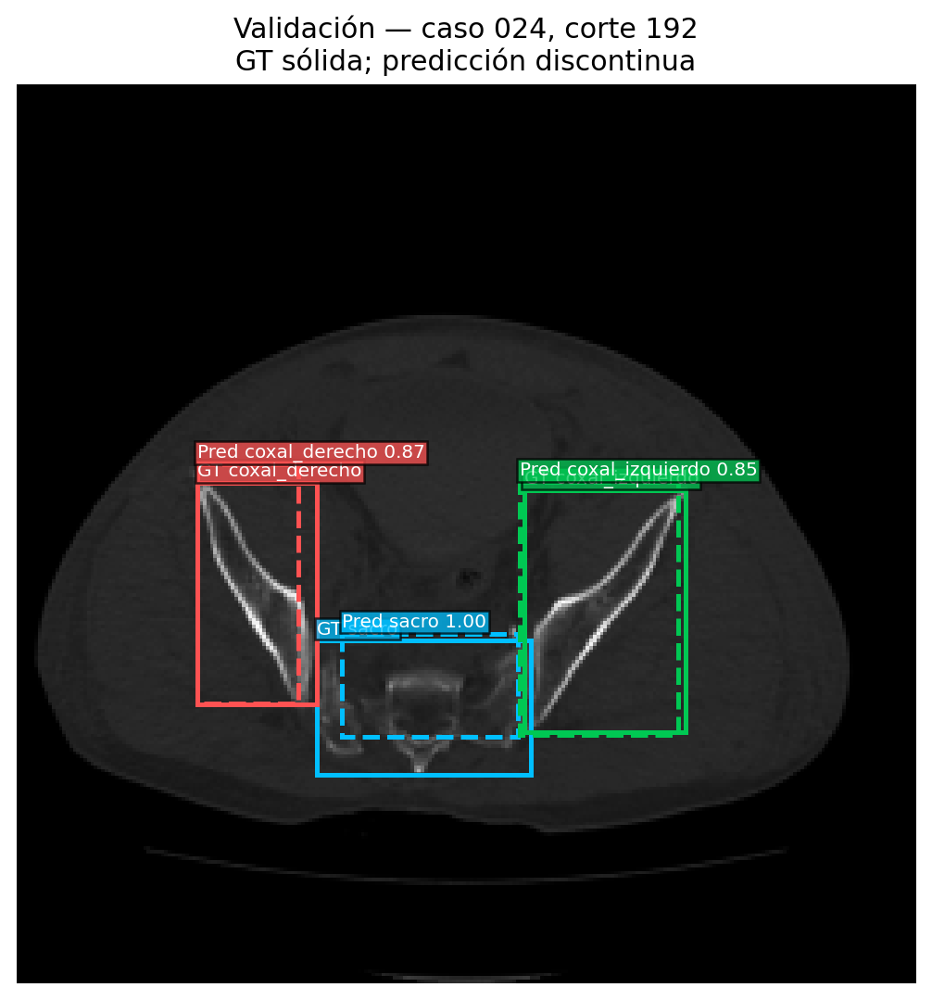

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 027 --output outputs/figures/week9_val_027.png
Guardado: outputs/figures/week9_val_027.png


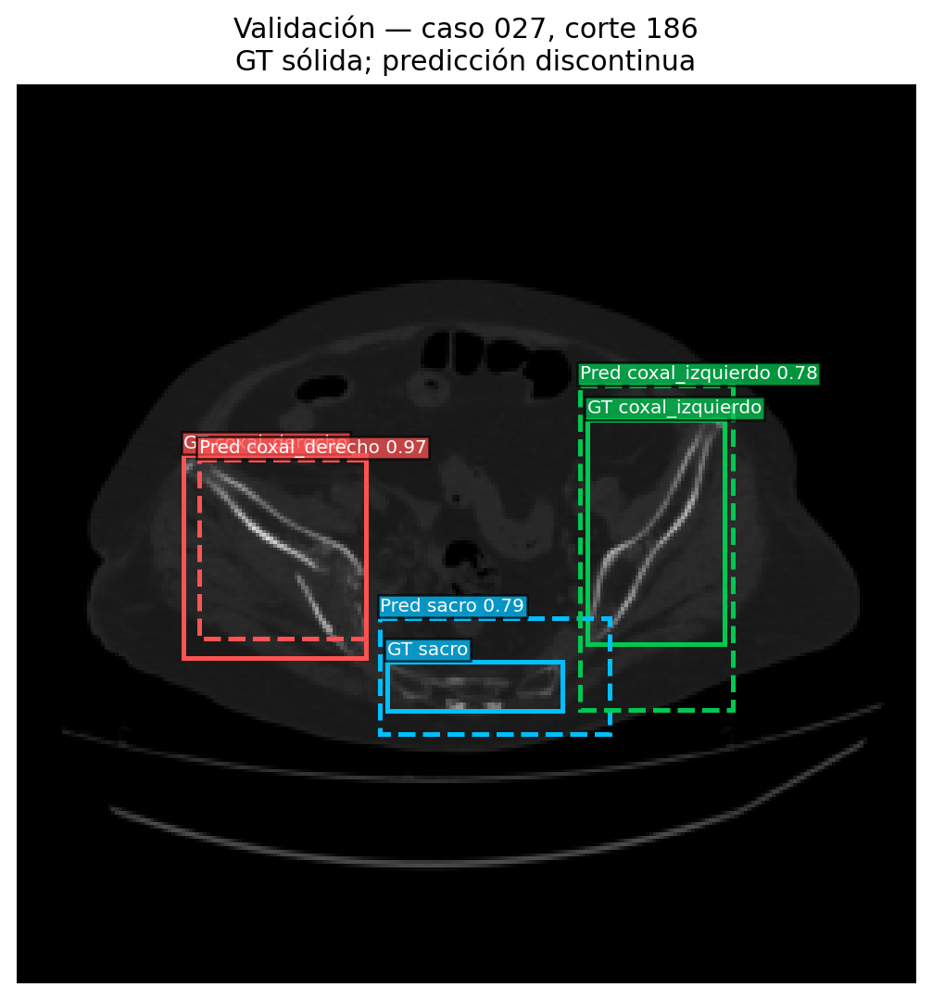

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 033 --output outputs/figures/week9_val_033.png
Guardado: outputs/figures/week9_val_033.png


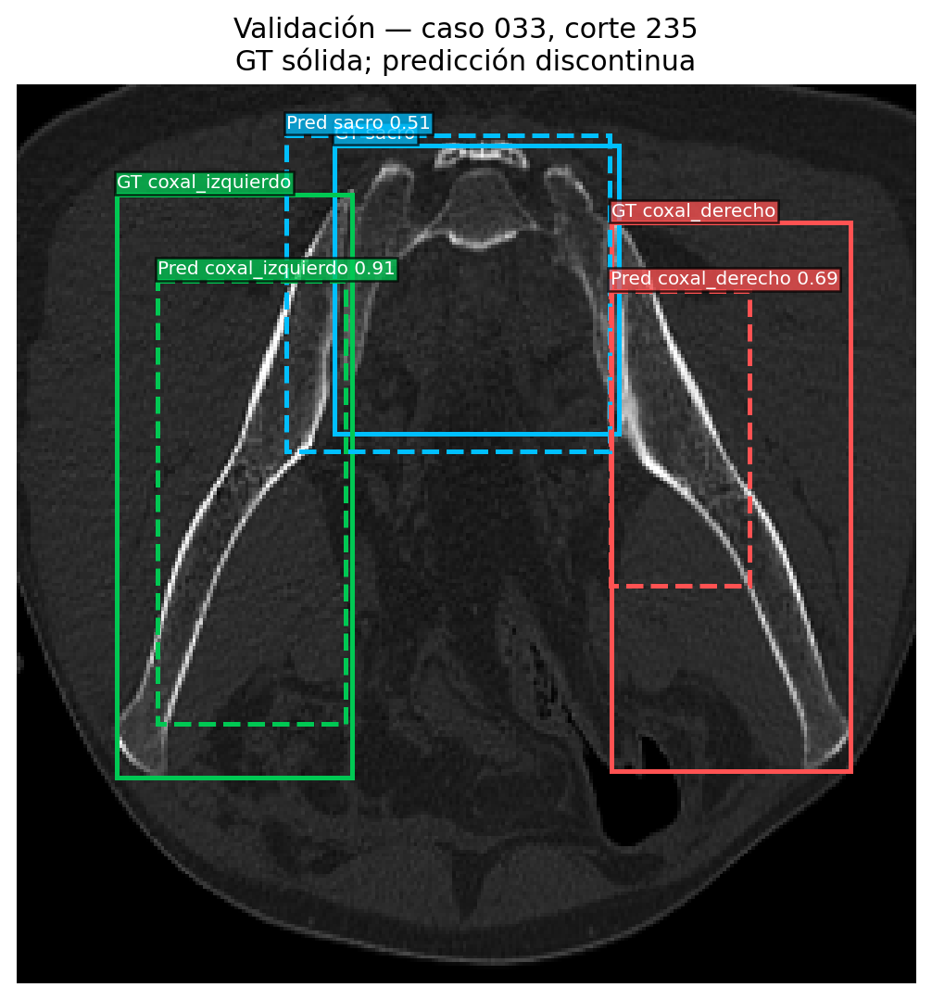

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 044 --output outputs/figures/week9_val_044.png
Guardado: outputs/figures/week9_val_044.png


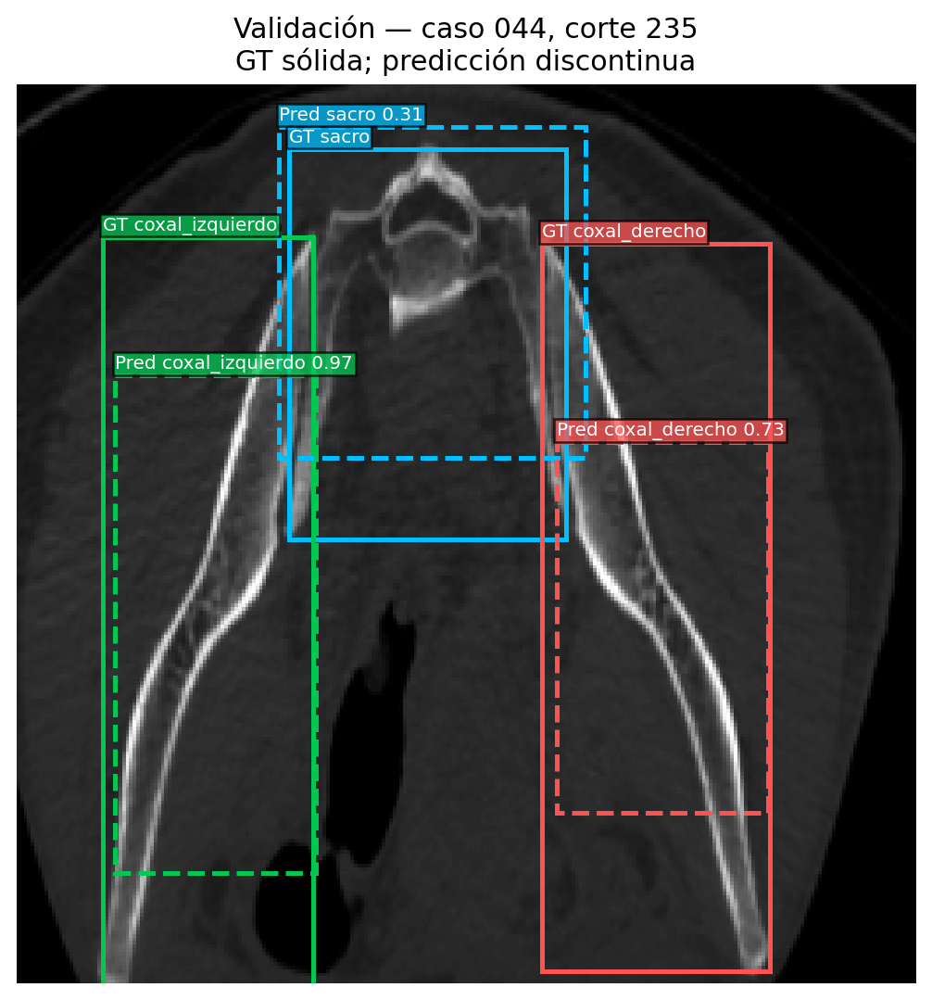

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 050 --output outputs/figures/week9_val_050.png
Guardado: outputs/figures/week9_val_050.png


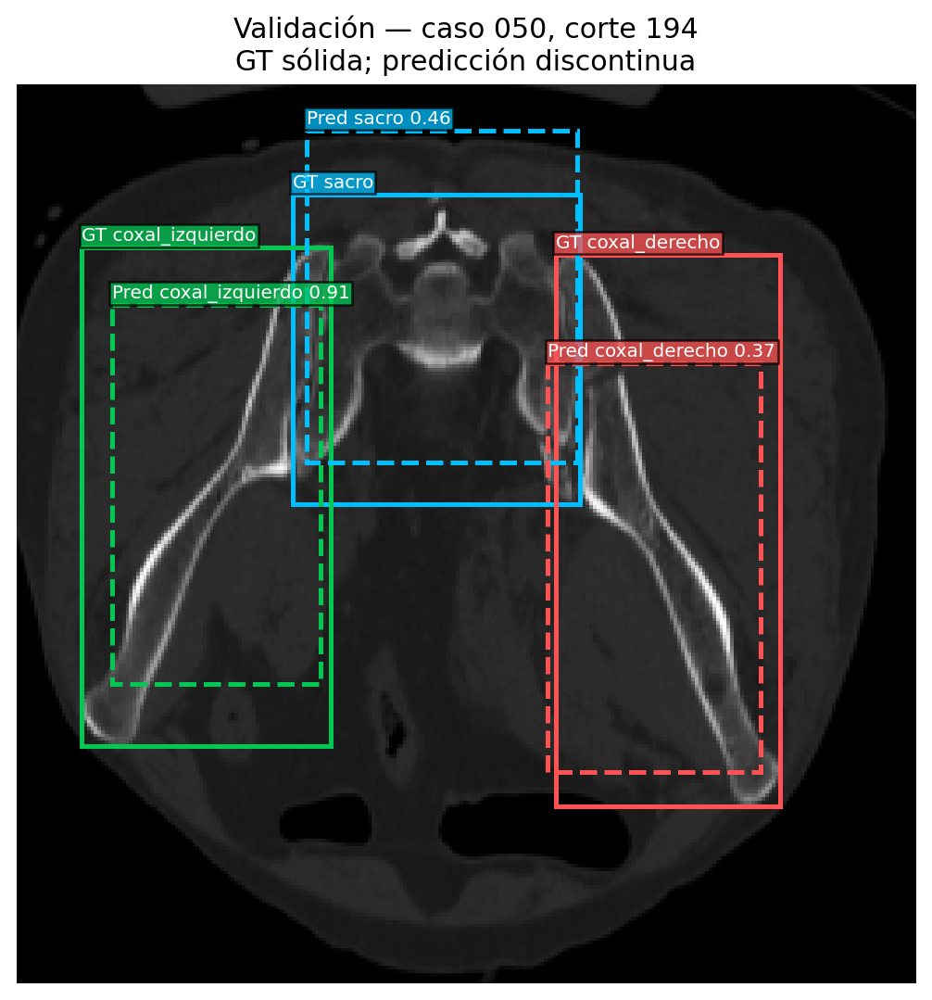

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 057 --output outputs/figures/week9_val_057.png
Guardado: outputs/figures/week9_val_057.png


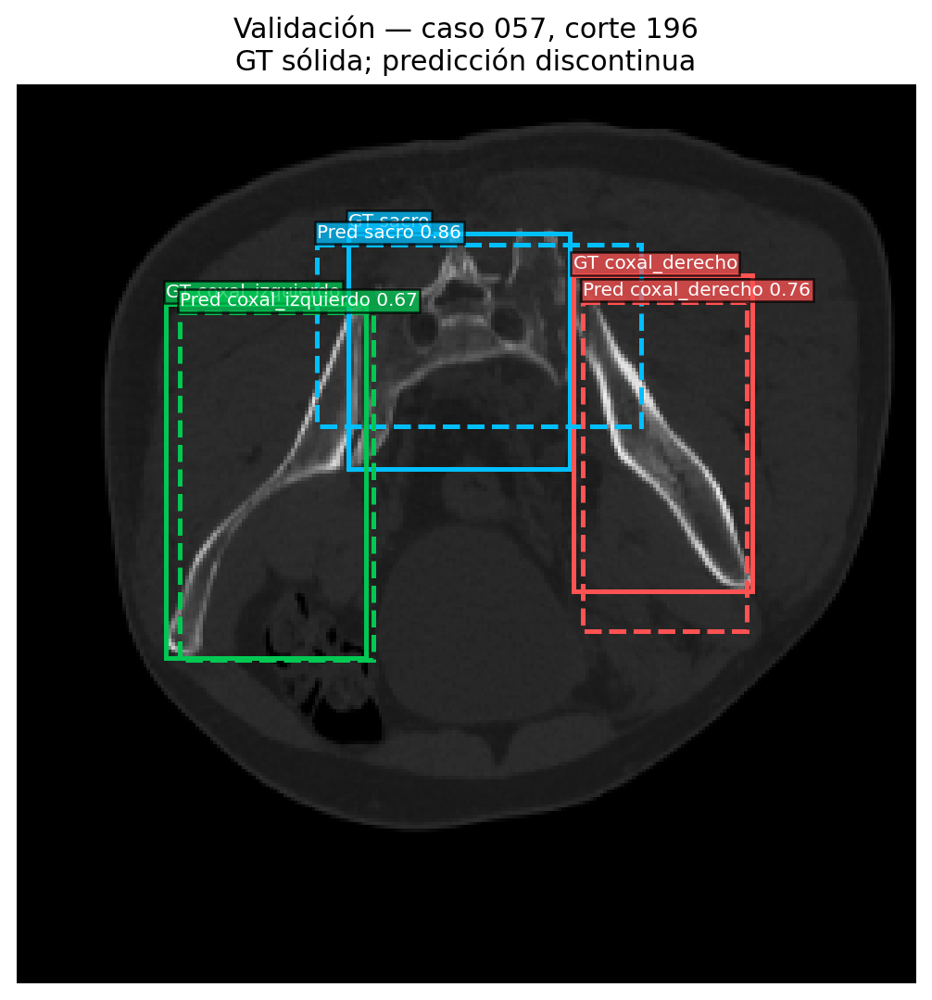

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 060 --output outputs/figures/week9_val_060.png
Guardado: outputs/figures/week9_val_060.png


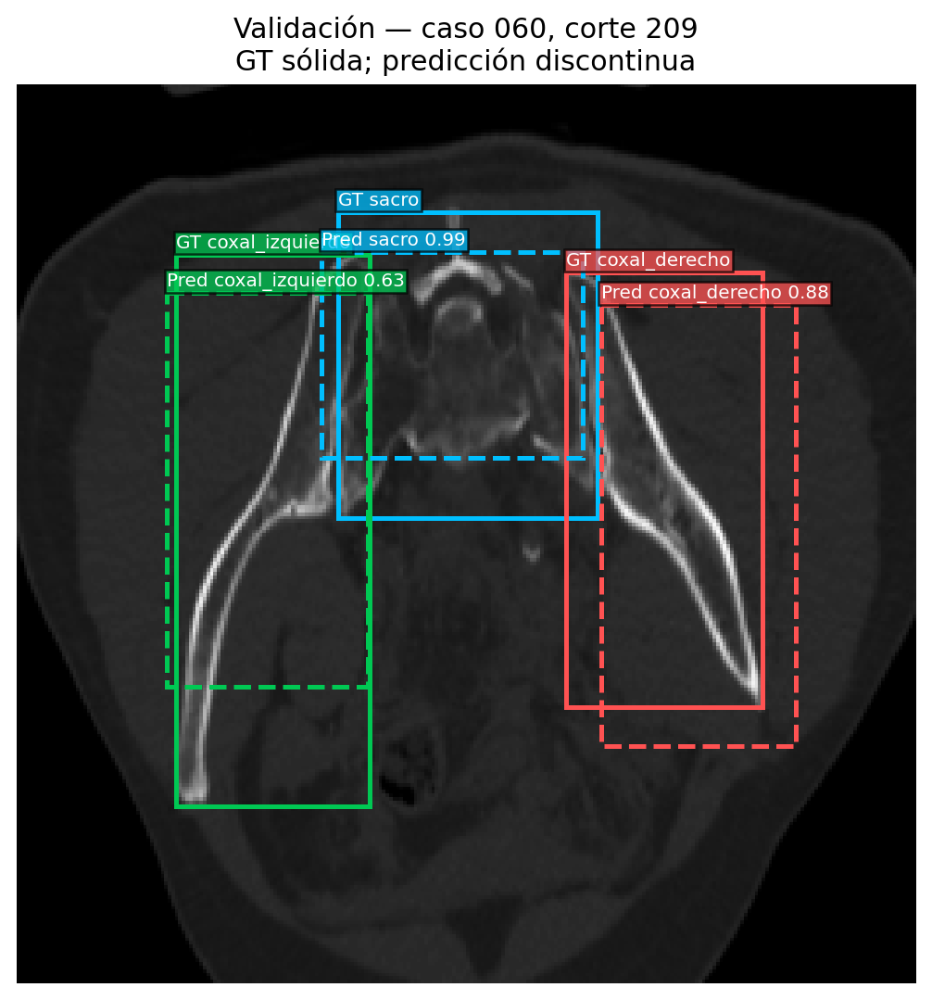

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 067 --output outputs/figures/week9_val_067.png
Guardado: outputs/figures/week9_val_067.png


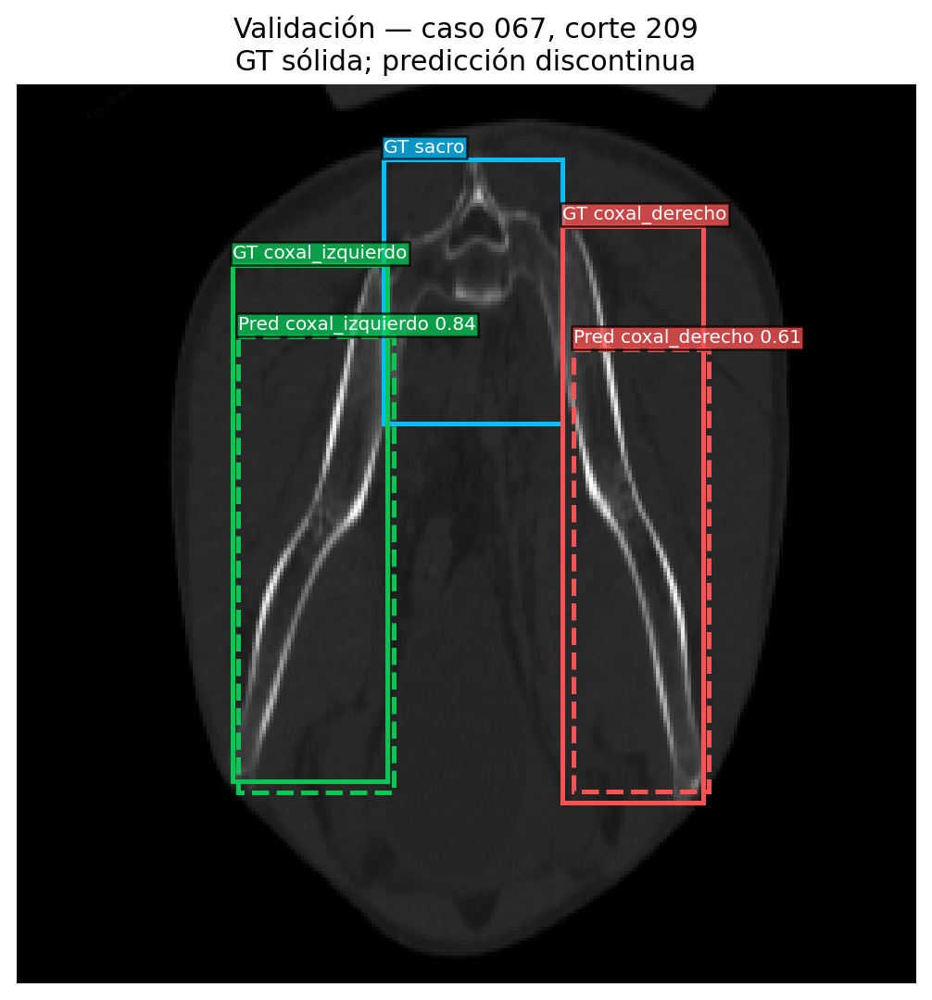

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 077 --output outputs/figures/week9_val_077.png
Guardado: outputs/figures/week9_val_077.png


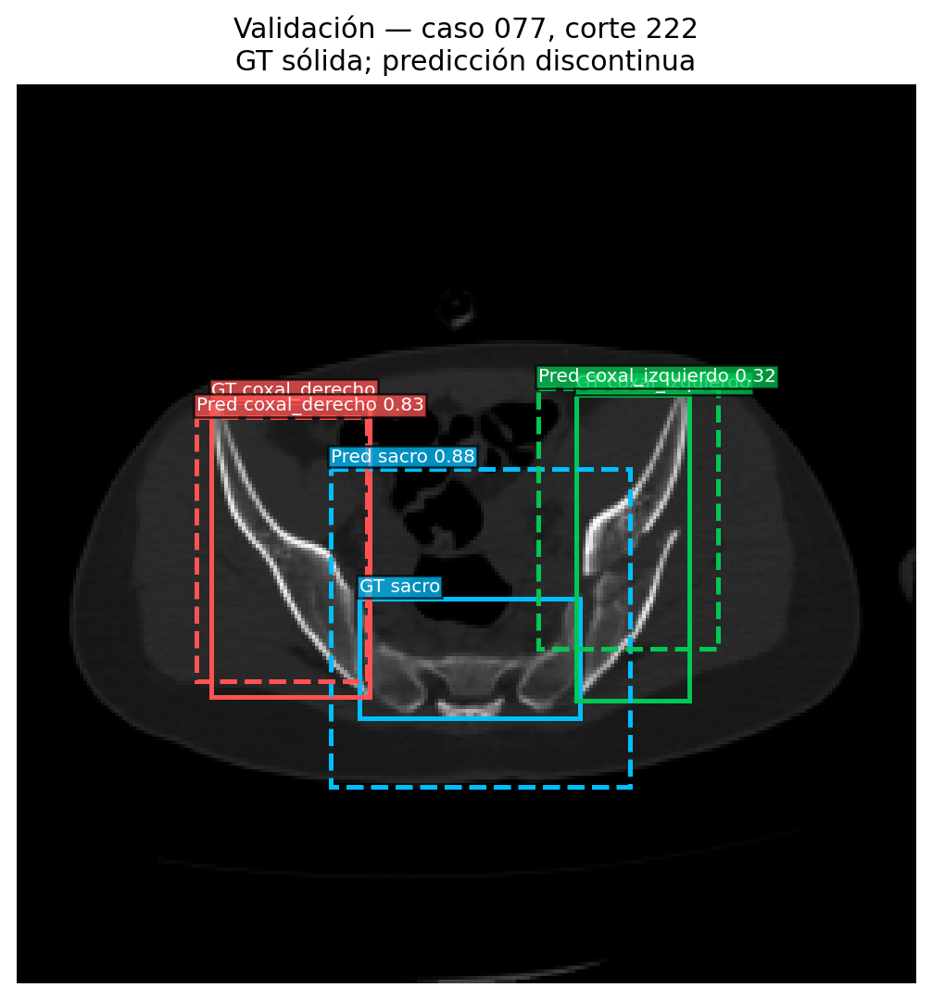

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 078 --output outputs/figures/week9_val_078.png
Guardado: outputs/figures/week9_val_078.png


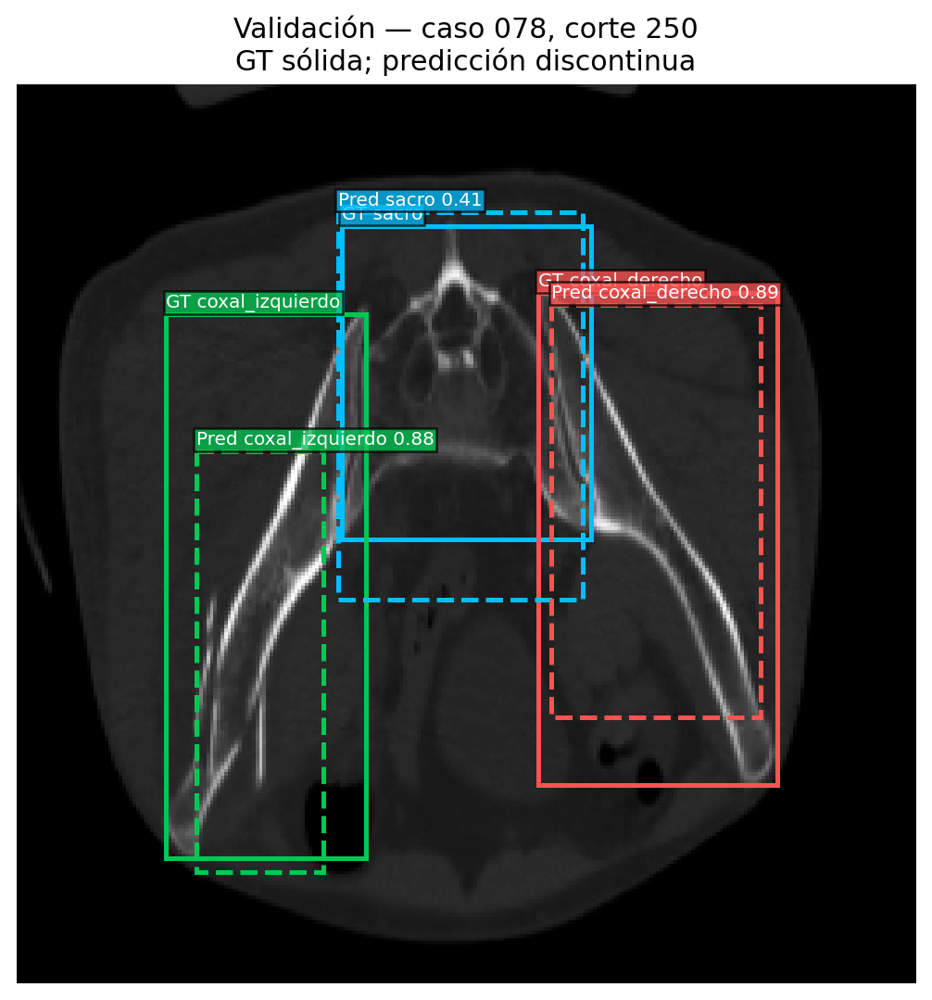

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 087 --output outputs/figures/week9_val_087.png
Guardado: outputs/figures/week9_val_087.png


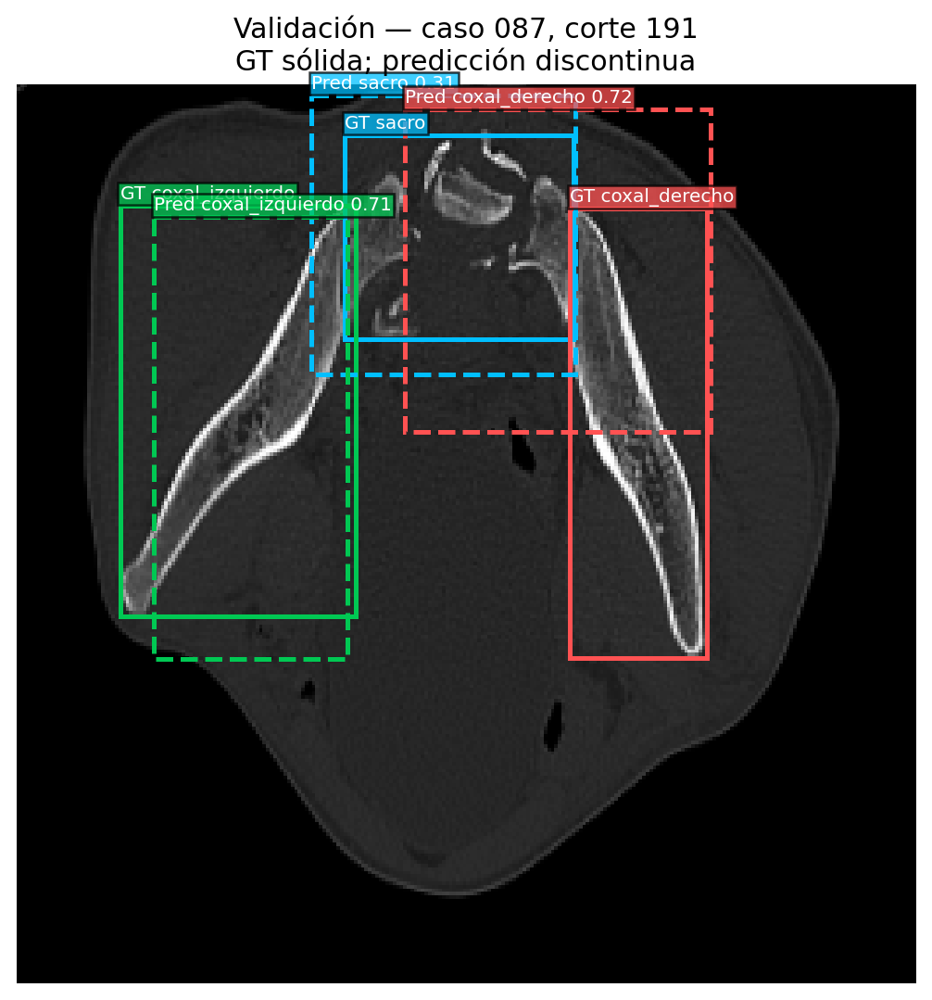

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 095 --output outputs/figures/week9_val_095.png
Guardado: outputs/figures/week9_val_095.png


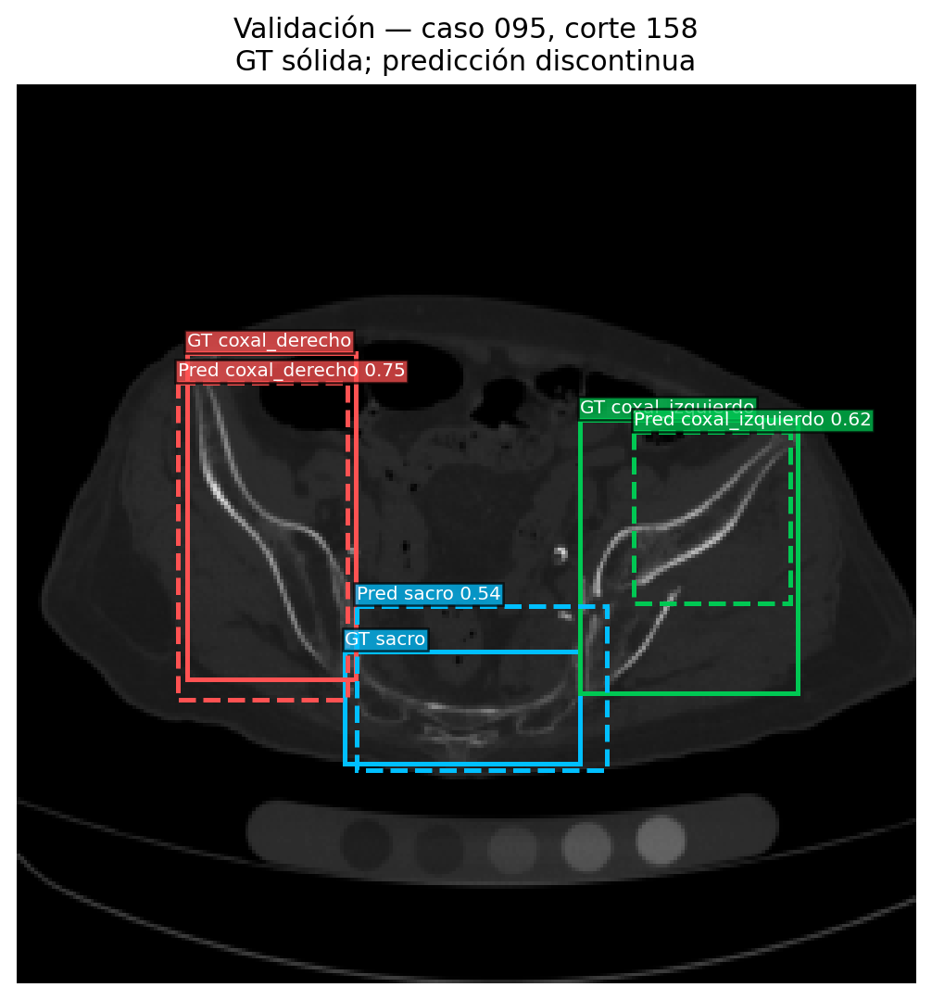

$ python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 099 --output outputs/figures/week9_val_099.png
Guardado: outputs/figures/week9_val_099.png


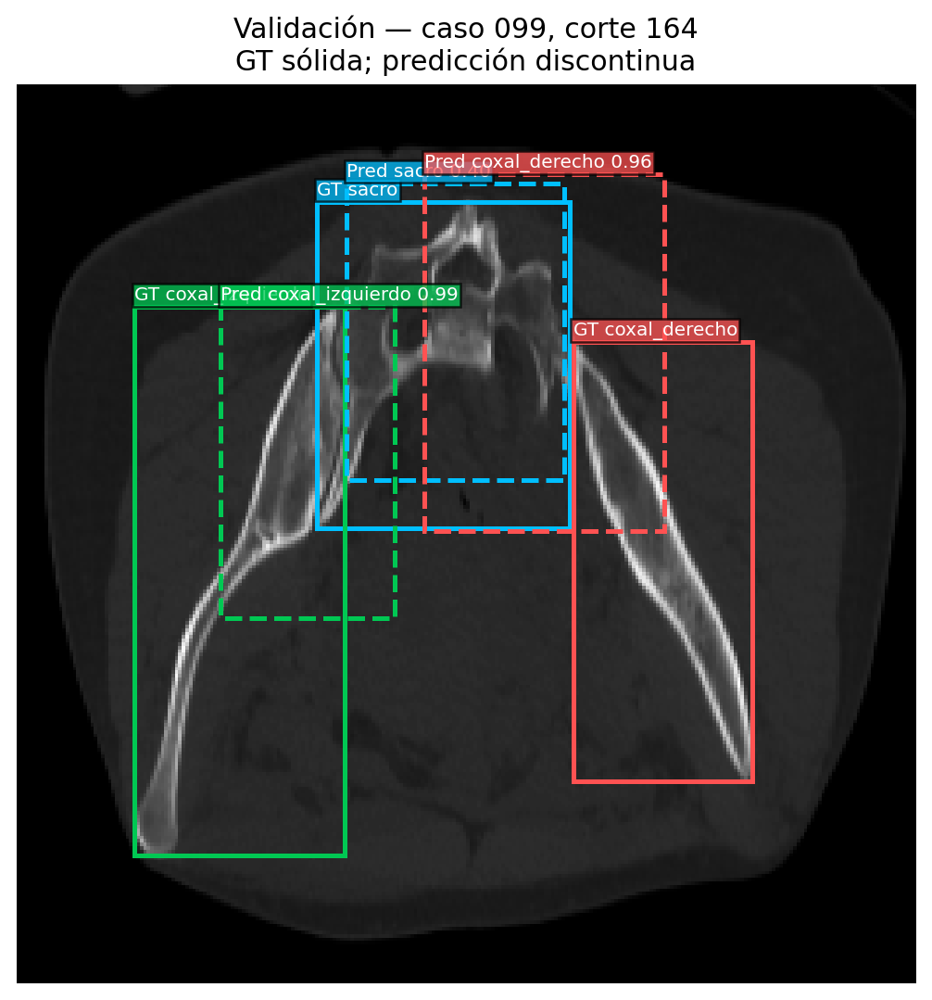

In [11]:
%matplotlib inline
val_ids = json.load(open('data/splits.json'))['val']
for cid in val_ids:
    cid = str(cid).zfill(3)
    run(f'python src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id {cid} --output outputs/figures/week9_val_{cid}.png')
    display(Image(f'outputs/figures/week9_val_{cid}.png', width=700))

## 100 casos uno debajo de otro

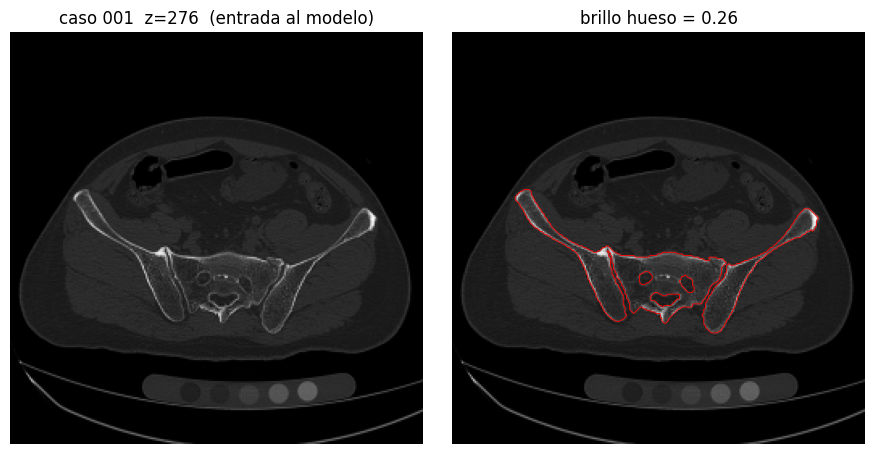

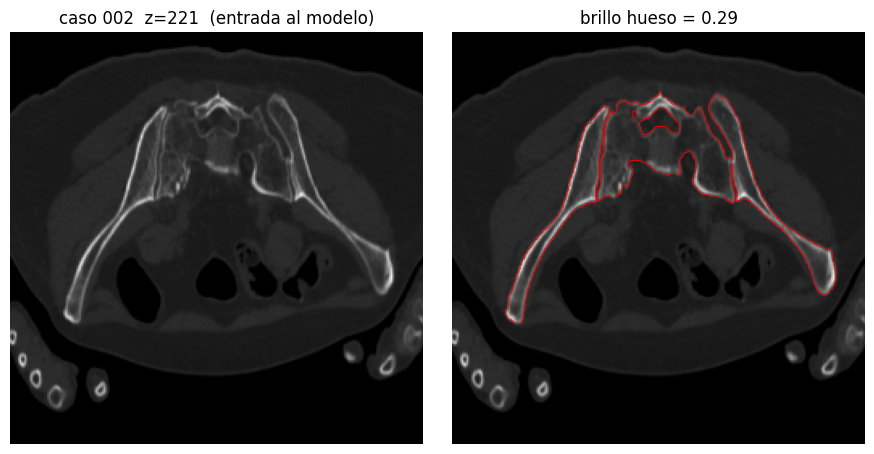

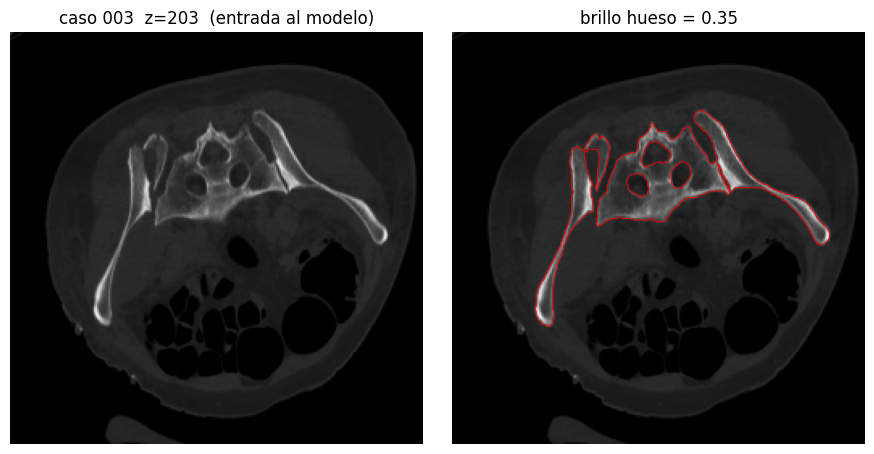

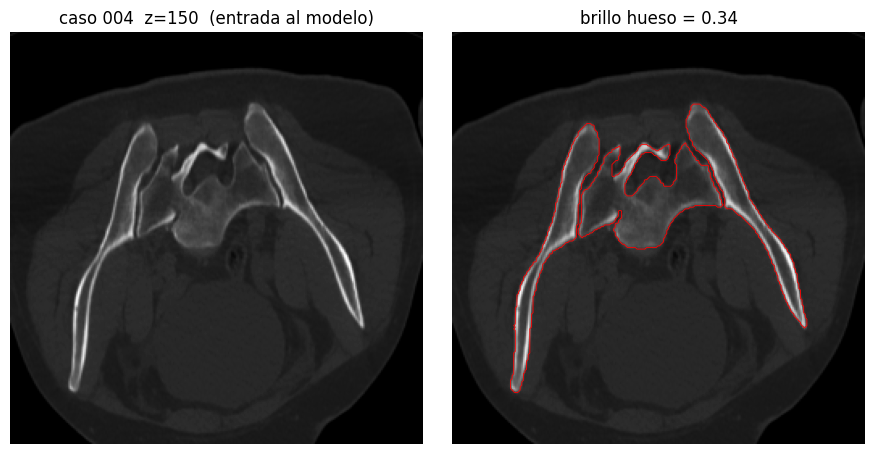

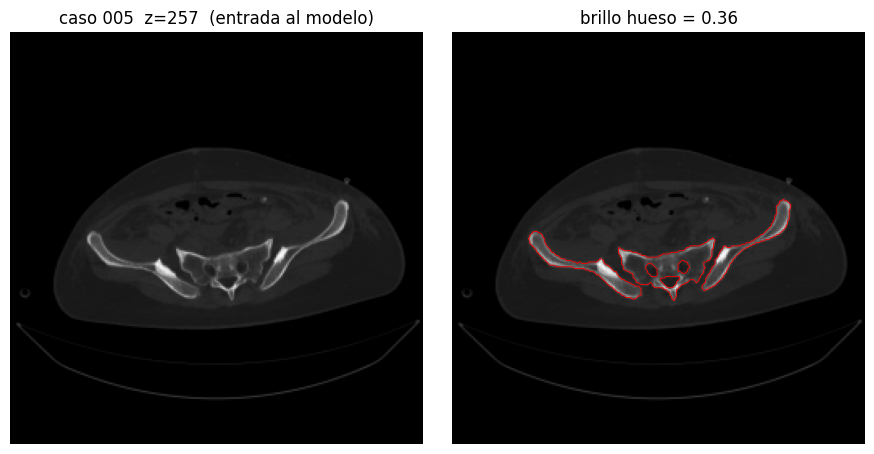

...

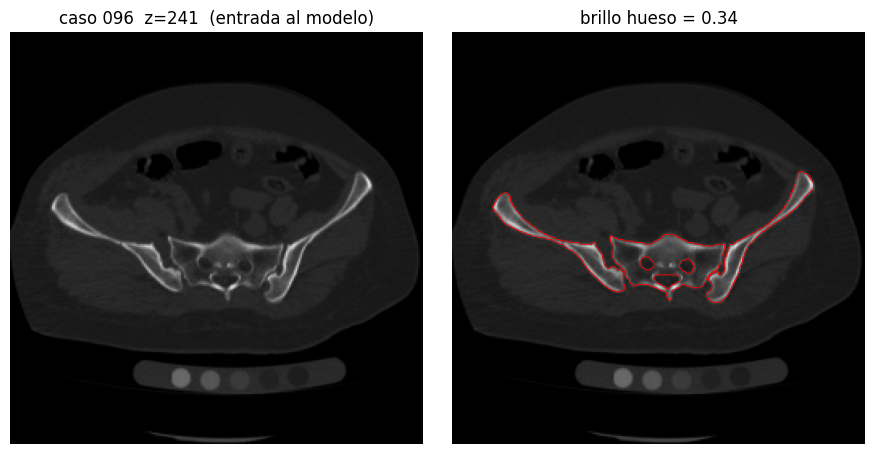

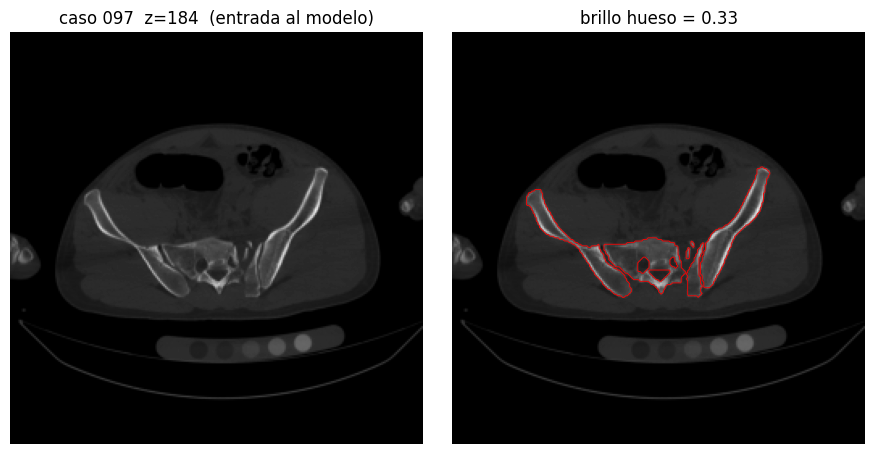

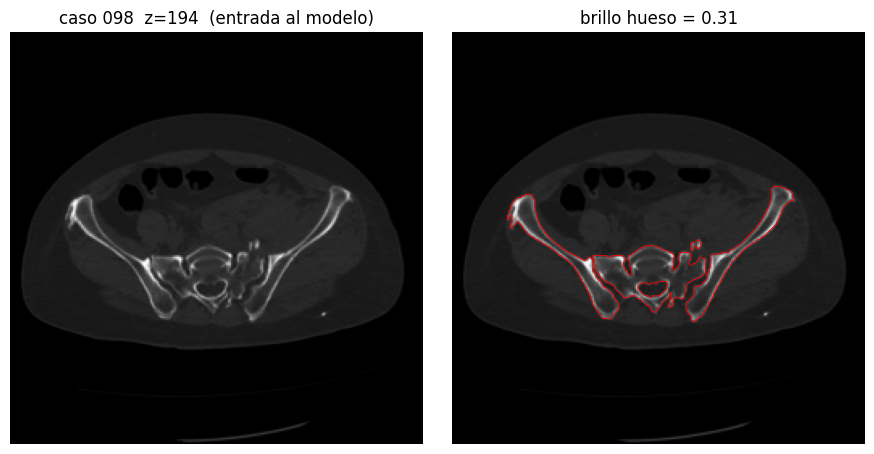

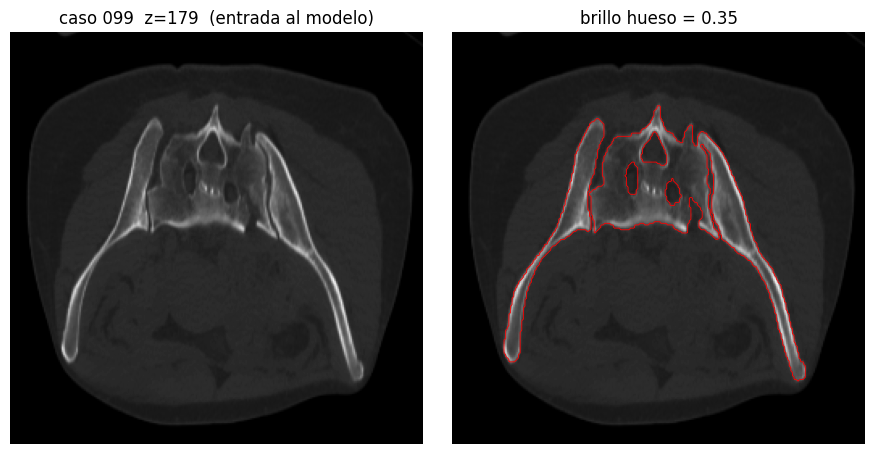

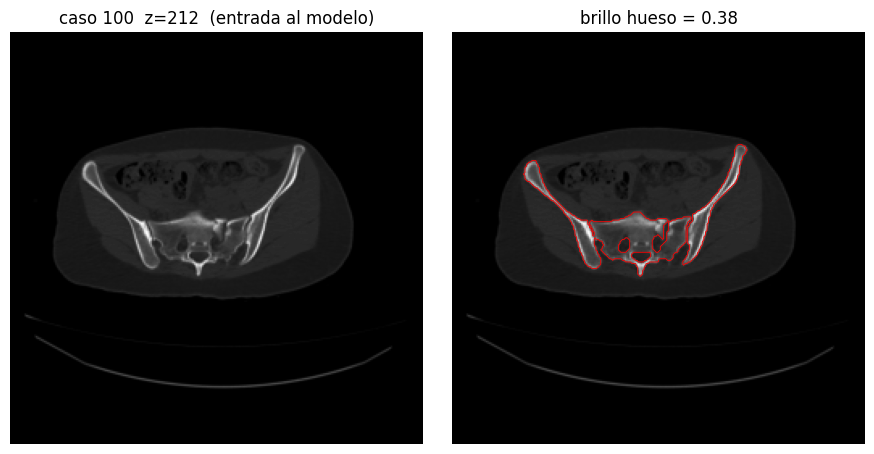

In [10]:
from pengwin_io import load_case, window_hu, resize_slice, resize_label_slice
from experimento_normalizacion import corte_con_mas_hueso
%matplotlib inline

out_dir = Path('outputs/figures/preproc_casos'); out_dir.mkdir(parents=True, exist_ok=True)
for cid in [f'{i:03d}' for i in range(1, 101)]:
    c = load_case(cid); z = corte_con_mas_hueso(c)
    img = resize_slice(window_hu(c.image[z]), 256); lab = resize_label_slice(c.label[z], 256)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=1); ax[0].set_title(f'caso {cid}  z={z}  (entrada al modelo)')
    ax[1].imshow(img, cmap='gray', vmin=0, vmax=1); ax[1].contour(lab > 0, levels=[0.5], colors='r', linewidths=0.6)
    ax[1].set_title(f'brillo hueso = {img[lab > 0].mean():.2f}')
    for a in ax: a.axis('off')
    plt.tight_layout(); fig.savefig(out_dir / f'{cid}.png', dpi=100); plt.show(); plt.close(fig)

## 6. Resumen para `docs/resumen_semana9.md`

Completar con los números de las celdas anteriores:

| Requisito | Evidencia | Resultado |
|---|---|---|
| Backbone + CBAM + cabeza de detección | `week9_detection.py`, celda 2 | grid 16×16, NMS propio, _N_ parámetros |
| Overfit sobre batch pequeño | `train_overfit_detection.py`, figura | pérdida _a_ → _b_ (_k_×, criterio ≥ 4×) |
| Primeras bboxes razonables | `train_week9_detection.py`, figura caso 014 | F1 val _x_ (con CBAM) vs _y_ (sin CBAM) |
| Preprocesamiento de entrada | `pengwin_io.window_hu`, `experimento_normalizacion.py` | gamma 1.5; CNR 8.1 vs 3.2 (CLAHE) vs 6.6 (ventana) |

**Decisiones de la semana:** gamma 1.5 en lugar de CLAHE (asesoría + barrido con evidencia); selección por F1 en lugar de IoU medio; 32 canales base (8 sobreajustaba 96 cortes); CBAM evaluado por ablación.

**Pendiente que arrastra a la semana 10:** los cachés y modelos de la semana 10 se entrenaron con CLAHE; con gamma como preprocesamiento definitivo hay que regenerarlos y reentrenar para que entrenamiento e inferencia usen la misma función.